# Model — BYOL Self-Supervised Pretraining + Segmentation Fine-tuning (Part B)

                   Group Members
|                      |               |
|Name	               | Student ID    |
|----------------------|---------------|
|Sumiaya Sharif	       | 2023-1-60-048 |
|                      |               |
|Ohiduzzaman Rayhan	   |2023-1-60-108  |
|                      |               |
|Prottoy Modak	       |2022-3-60-130  |
|                      |               |
|Afrina Alam Lamia	   |2022-1-60-231  |
|                                      |

Dataset
Dataset Name: FoodBD (FoodBD: A Polygon-Annotated Meal Image Dataset)

## Setup & imports (version pins)

In [12]:
!pip install -q --no-deps "albumentations==1.4.15" "albucore==0.0.16"
!pip install -q opencv-python-headless==4.10.0.84

In [13]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [14]:
import os, sys, json, time, random, math, copy
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models import resnet50, ResNet50_Weights
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch:", torch.__version__, "| torchvision:", torchvision.__version__)

Device: cuda | torch: 2.10.0+cu128 | torchvision: 0.25.0+cu128


## Master config cell — PASTE YOUR PART-A / PART-B-DATAPREP KAGGLE DATASET PATHS HERE

In [15]:
CONFIG = {
    # ============================================================================
    # >>> PASTE YOUR PART-A / PART-B-DATAPREP KAGGLE DATASET PATHS BELOW <<<
    # Kaggle editor -> right panel -> "Add Input" -> attach these 3 datasets -> copy
    # each dataset's /kaggle/input/... path into the 3 lines below.
    #   1) nb0_dataset_slug   -> Part-A NB0 output dataset (common_config.json, seg_common.py)
    #   2) dataprep_dir_slug  -> Part-B "Data Prep" notebook's output dataset
    #                            (partb_config.json, split_manifest_remapped.json, ssl_common.py)
    #   3) raw_dataset_slug   -> the raw FoodBD image dataset (same copy used in Part A)
    # These are identical to what your DINOv2 notebook used -- reuse the same 3 paths so the
    # train/valid/test role-mapping stays apples-to-apples across all 4 SSL methods (Sec. 2 of PDF).
    # ============================================================================
    "nb0_dataset_slug":  "/kaggle/input/datasets/afrinaalam/nb0-artifacts",   # <-- PASTE Part-A NB0 dataset path
    "dataprep_dir_slug": "/kaggle/input/datasets/afrinaalam/partb-outputs",   # <-- PASTE Part-B data-prep dataset path
    "raw_dataset_slug":  "/kaggle/input/datasets/prottoymodak7/foodbd-2",        # <-- PASTE raw FoodBD dataset path
    # ============================================================================

    "out_dir": "/kaggle/working/byol_outputs",

    # --- BYOL backbone ---
    # Path-1 (recommended by the PDF, Sec 3.2 compute-budget note) is normally "load an official
    # SSL-pretrained checkpoint and continue SSL pretraining". No torchvision-loadable official BYOL
    # checkpoint is reachable from an offline Kaggle session, so we warm-start from torchvision's
    # ImageNet-*supervised* ResNet-50 instead and then run full BYOL self-supervised pretraining on
    # top of it for the required 50 epochs. State this choice explicitly in report Sec. 6.4.
    "backbone_note": "resnet50 (torchvision IMAGENET1K_V2 supervised init) + 50ep BYOL SSL continuation",

    "ssl_crop_size": 224,          # standard BYOL pretraining resolution -- ResNet-50 is fully
                                    # convolutional (no patch-grid constraint like DINOv2's ViT-14),
                                    # so this is free to differ from the seg resolution used in Task D/E
    "ssl_epochs": 50,
    "ssl_batch_size": 32,
    "ssl_base_lr": 3e-2,           # SGD (LARS substitute -- see markdown note above the build cell)
    "ssl_min_lr": 0.0,
    "ssl_warmup_epochs": 10,
    "ssl_weight_decay": 1.5e-6,    # BYOL paper value, fixed (not scheduled, unlike DINO's wd_sched)
    "ssl_momentum_target": (0.996, 1.0),   # EMA tau range for the target network, cosine-scheduled

    "proj_hidden_dim": 4096,       # BYOL paper: projector/predictor hidden dim
    "proj_out_dim": 256,           # BYOL paper: projector/predictor output dim

    "decoder_embed_dim": 256,
    "ft_epochs": 50,
    "ft_batch_size": 8,
    "ft_lr_encoder": 1e-5,
    "ft_lr_decoder": 1e-4,
    "ft_weight_decay": 1e-4,
    "encoder_mode": "finetune",

    "seed": SEED,
}
os.makedirs(CONFIG["out_dir"], exist_ok=True)
print(json.dumps(CONFIG, indent=2, default=str))

{
  "nb0_dataset_slug": "/kaggle/input/datasets/afrinaalam/nb0-artifacts",
  "dataprep_dir_slug": "/kaggle/input/datasets/afrinaalam/partb-outputs",
  "raw_dataset_slug": "/kaggle/input/datasets/prottoymodak7/foodbd-2",
  "out_dir": "/kaggle/working/byol_outputs",
  "backbone_note": "resnet50 (torchvision IMAGENET1K_V2 supervised init) + 50ep BYOL SSL continuation",
  "ssl_crop_size": 224,
  "ssl_epochs": 50,
  "ssl_batch_size": 32,
  "ssl_base_lr": 0.03,
  "ssl_min_lr": 0.0,
  "ssl_warmup_epochs": 10,
  "ssl_weight_decay": 1.5e-06,
  "ssl_momentum_target": [
    0.996,
    1.0
  ],
  "proj_hidden_dim": 4096,
  "proj_out_dim": 256,
  "decoder_embed_dim": 256,
  "ft_epochs": 50,
  "ft_batch_size": 8,
  "ft_lr_encoder": 1e-05,
  "ft_lr_decoder": 0.0001,
  "ft_weight_decay": 0.0001,
  "encoder_mode": "finetune",
  "seed": 42
}


## Load Task-A split roles (Part-A splits, reused unmodified)

In [16]:
def _resolve(slug):
    return slug if slug.startswith("/") else f"/kaggle/input/{slug}"

def _find_dir_containing(root, filename):
    """Kaggle sometimes mounts a dataset one folder deeper than its top-level slug
    (e.g. /kaggle/input/<slug>/<slug>/...), so a file you expect at DIR/file.py can
    actually sit at DIR/<something>/file.py. Search subfolders before giving up."""
    if os.path.exists(os.path.join(root, filename)):
        return root
    for dirpath, dirnames, filenames in os.walk(root):
        if filename in filenames:
            return dirpath
    return None

# --- NB0 artifacts (Part-A's seg_common.py + common_config.json) ---
NB0_DIR = _resolve(CONFIG["nb0_dataset_slug"])
_found = _find_dir_containing(NB0_DIR, "common_config.json")
assert _found is not None, (
    f"common_config.json not found anywhere under {NB0_DIR}. "
    f"Run `!ls -R /kaggle/input` and fix CONFIG['nb0_dataset_slug'] above."
)
NB0_DIR = _found
sys.path.insert(0, NB0_DIR)
from seg_common import load_common_config, load_split_manifest, polygons_to_mask, get_transforms, FoodSegDataset

cfg = load_common_config(f"{NB0_DIR}/common_config.json")
IMG_SIZE_PARTA = cfg["img_size"]              # 512, Part-A's resolution -- reused as-is (no forcing needed)
NUM_CLASSES = cfg["num_classes_total"]        # 68 (67 food classes + background)
CLASS_NAMES = ["background"] + cfg["class_names"]
CONFIG["num_classes"] = NUM_CLASSES
print(f"NUM_CLASSES={NUM_CLASSES} | Part-A/BYOL fine-tune IMG_SIZE={IMG_SIZE_PARTA} | SSL crop size={CONFIG['ssl_crop_size']}")

# --- Part-B role-mapped split (Task A, already produced by the Data Prep notebook) ---
DATAPREP_DIR = _resolve(CONFIG["dataprep_dir_slug"])
_found = _find_dir_containing(DATAPREP_DIR, "ssl_common.py")
assert _found is not None, (
    f"ssl_common.py not found anywhere under {DATAPREP_DIR}. "
    f"Run `!ls -R /kaggle/input` and fix CONFIG['dataprep_dir_slug'] above -- "
    f"make sure your Part-B Data Prep notebook's output dataset is attached."
)
DATAPREP_DIR = _found
sys.path.insert(0, DATAPREP_DIR)
from ssl_common import load_partb_config, load_remapped_split

_cfg_dir = _find_dir_containing(DATAPREP_DIR, "partb_config.json") or DATAPREP_DIR
_split_dir = _find_dir_containing(DATAPREP_DIR, "split_manifest_remapped.json") or DATAPREP_DIR
partb_cfg = load_partb_config(f"{_cfg_dir}/partb_config.json")
splits = load_remapped_split(f"{_split_dir}/split_manifest_remapped.json")

# --- point paths at whichever raw-dataset copy you actually attached ---
BAKED_ROOT = cfg["data_root"]
RAW_ROOT = f"{_resolve(CONFIG['raw_dataset_slug'])}/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD"

def _remap(p):
    return p.replace(BAKED_ROOT, RAW_ROOT) if isinstance(p, str) else p

for key in ["train", "valid", "test"]:
    splits[key] = [_remap(p) for p in splits[key]]

train_imgs = splits["train"]   # unlabelled BYOL pretraining corpus (Task B)
valid_imgs = splits["valid"]   # labelled fine-tuning set (Task D)
test_imgs  = splits["test"]    # downstream monitoring + final eval (Task D & E, double role)

_missing = [p for p in (train_imgs[:3] + valid_imgs[:3] + test_imgs[:3]) if not os.path.exists(p)]
if _missing:
    print("RAW DATASET NOT FOUND at:")
    for p in _missing: print("  ", p)
    print("\nMounted under /kaggle/input:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if files: print("  ", root, "->", len(files), "files, e.g.", files[0])
    raise FileNotFoundError("Attach the raw FoodBD dataset, or fix CONFIG['raw_dataset_slug'] above.")
print(f"Paths resolve OK. train={len(train_imgs)} valid={len(valid_imgs)} test={len(test_imgs)}")

sample_label = train_imgs[0].replace("/images/", "/labels/").rsplit(".",1)[0] + ".txt"
print("Sample label file exists:", os.path.exists(sample_label), "->", sample_label)

NUM_CLASSES=68 | Part-A/BYOL fine-tune IMG_SIZE=512 | SSL crop size=224
Paths resolve OK. train=2473 valid=697 test=353
Sample label file exists: True -> /kaggle/input/datasets/prottoymodak7/foodbd-2/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/labels/FoodBD-0002.txt


## Transforms — BYOL two-view augmentation (Task B) + reused Part-A synced transforms (Task D/E)

In [17]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# Task B augmentation -- asymmetric view1/view2 per the original BYOL paper (Grill et al. 2020,
# App. B): view1 is *always* blurred and never solarized; view2 is rarely blurred and sometimes
# solarized. This asymmetry (not present in DINOv2's global/local multi-crop) is what the PDF's
# viva question "which transforms are essential to the pretext task and why" is asking about here.
_shared_aug = [
    A.RandomResizedCrop(size=(CONFIG["ssl_crop_size"], CONFIG["ssl_crop_size"]),
                         scale=(0.08, 1.0), ratio=(0.75, 1.33)),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(0.4, 0.4, 0.2, 0.1, p=0.8),
    A.ToGray(p=0.2),
]
view1_tf = A.Compose(_shared_aug + [
    A.GaussianBlur(blur_limit=(3, 7), p=1.0),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])
view2_tf = A.Compose(_shared_aug + [
    A.GaussianBlur(blur_limit=(3, 7), p=0.1),
    A.Solarize(threshold=128, p=0.2),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# Task D/E: identical synced image+mask pipeline as Part-A -- ResNet-50 has no patch-grid
# constraint (unlike DINOv2's ViT-14, which forced 512 -> 518), so we fine-tune/evaluate at
# Part-A's *native* resolution directly.
IMG_SIZE = IMG_SIZE_PARTA
finetune_tf = get_transforms(IMG_SIZE, train=True)    # labelled fine-tune (valid split)
eval_tf     = get_transforms(IMG_SIZE, train=False)   # deterministic (test split)

## Datasets — BYOLTwoViewDataset (unlabelled) + reused FoodSegDataset (labelled)

In [18]:
class BYOLTwoViewDataset(Dataset):
    """Task B: images-only, no masks. BYOL uses exactly two views per image (unlike DINOv2's
    2-global + N-local multi-crop) -- one pair is all the pretext task needs."""
    def __init__(self, img_paths, view1_tf, view2_tf):
        self.img_paths = img_paths
        self.view1_tf, self.view2_tf = view1_tf, view2_tf

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(str(self.img_paths[idx])), cv2.COLOR_BGR2RGB)
        v1 = self.view1_tf(image=img)["image"]
        v2 = self.view2_tf(image=img)["image"]
        return v1, v2

ssl_ds = BYOLTwoViewDataset(train_imgs, view1_tf, view2_tf)

# Task D & E: reuse Part-A's exact FoodSegDataset (polygon->mask logic), same bg_is_zero flag
ft_ds   = FoodSegDataset(valid_imgs, finetune_tf, bg_is_zero=cfg["bg_is_zero"])
test_ds = FoodSegDataset(test_imgs,  eval_tf,     bg_is_zero=cfg["bg_is_zero"])

ssl_loader  = DataLoader(ssl_ds, batch_size=CONFIG["ssl_batch_size"], shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True)
ft_loader   = DataLoader(ft_ds, batch_size=CONFIG["ft_batch_size"], shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True)
test_loader = DataLoader(test_ds, batch_size=CONFIG["ft_batch_size"], shuffle=False,
                          num_workers=4, pin_memory=True)

print(f"SSL batches/epoch: {len(ssl_loader)} | FT batches/epoch: {len(ft_loader)} | Test batches: {len(test_loader)}")

SSL batches/epoch: 77 | FT batches/epoch: 87 | Test batches: 45


## Sanity checks

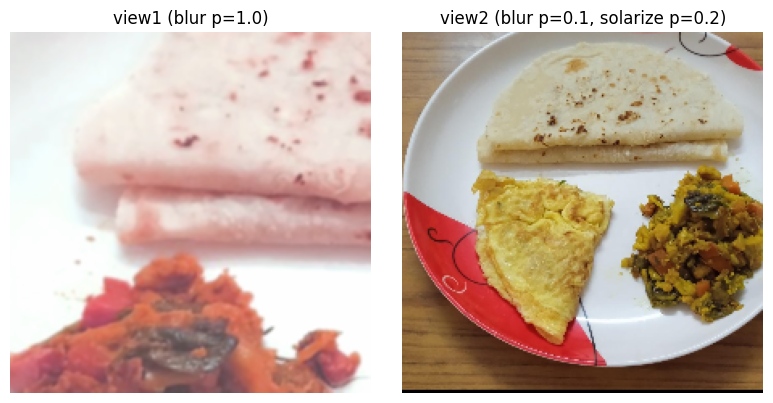

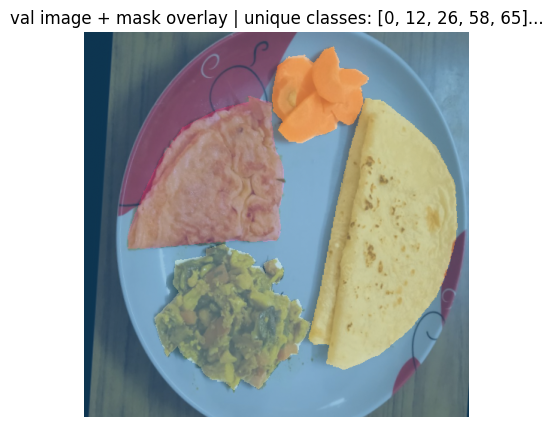

In [19]:
def denorm(t):
    m = np.array(IMAGENET_MEAN).reshape(3,1,1); s = np.array(IMAGENET_STD).reshape(3,1,1)
    x = t.numpy() * s + m
    return np.clip(x.transpose(1,2,0), 0, 1)

# (a) view1 vs view2 of the same unlabelled train image -- note the visible asymmetry
# (view1 always blurred; view2 sometimes solarized) that the BYOL paper prescribes
v1_sample, v2_sample = ssl_ds[0]
fig, axes = plt.subplots(1, 2, figsize=(8,4))
axes[0].imshow(denorm(v1_sample)); axes[0].set_title("view1 (blur p=1.0)"); axes[0].axis("off")
axes[1].imshow(denorm(v2_sample)); axes[1].set_title("view2 (blur p=0.1, solarize p=0.2)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

# (b) validation-split image with mask overlay -- CHECK THIS LOOKS RIGHT before trusting it
img_t, mask_t = ft_ds[0]
img_np = denorm(img_t)
fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.imshow(img_np)
ax.imshow(mask_t.numpy(), alpha=0.45, cmap="tab20")
ax.set_title(f"val image + mask overlay | unique classes: {torch.unique(mask_t).tolist()[:10]}...")
ax.axis("off")
plt.show()

## ResNet-50 backbone + Task-C adapter (multi-scale feature maps → common resolution)

In [20]:
class ResNet50Encoder(nn.Module):
    """Wraps torchvision resnet50. Exposes two forward paths off the SAME weights:
      - forward_pooled():    global-avg-pooled C5 feature -> BYOL's instance-level pretext task (Task B)
      - forward_multiscale(): C2/C3/C4/C5 feature pyramid  -> segmentation decoder input (Task C-F)
    """
    def __init__(self, pretrained_imagenet=True):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained_imagenet else None
        net = resnet50(weights=weights)
        self.stem   = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1 = net.layer1   # C2, stride 4,  256ch
        self.layer2 = net.layer2   # C3, stride 8,  512ch
        self.layer3 = net.layer3   # C4, stride 16, 1024ch
        self.layer4 = net.layer4   # C5, stride 32, 2048ch
        self.out_channels = [256, 512, 1024, 2048]

    def forward_multiscale(self, x):
        x  = self.stem(x)
        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)
        return [c2, c3, c4, c5]

    def forward_pooled(self, x):
        c5 = self.forward_multiscale(x)[-1]
        return F.adaptive_avg_pool2d(c5, 1).flatten(1)   # (B, 2048)

## BYOL projector/predictor heads, EMA target update, BYOL loss (Task B)

In [21]:
# built with AI assistance (Claude) -- disclosed per Sec. 7 AI Usage Policy

class MLPHead(nn.Module):
    """Shared building block for BYOL's projector and predictor (Grill et al. 2020, Fig 2):
    Linear -> BatchNorm1d -> ReLU -> Linear, no final activation."""
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        return self.net(x)


class BYOLNet(nn.Module):
    """online branch: representation -> projector -> predictor -> prediction
       target branch: representation -> projector -> projection   (no predictor, no grad)"""
    def __init__(self, encoder, proj_hidden, proj_out, is_online):
        super().__init__()
        self.encoder = encoder
        self.projector = MLPHead(encoder.out_channels[-1], proj_hidden, proj_out)
        self.predictor = MLPHead(proj_out, proj_hidden, proj_out) if is_online else None

    def forward(self, x):
        rep = self.encoder.forward_pooled(x)          # (B, 2048) global-pooled instance representation
        proj = self.projector(rep)
        return self.predictor(proj) if self.predictor is not None else proj


def byol_loss(p, z):
    """Negative-free normalized-MSE loss (Grill et al. 2020, Eq. 2): 2 - 2*cos_sim(p, z).
    z (the target branch's output) is always detached by the caller before this is called --
    there are no negative pairs anywhere in this loss, which is exactly why BYOL needs the
    stop-gradient + EMA-target trick to avoid collapsing to a trivial constant."""
    p = F.normalize(p, dim=-1)
    z = F.normalize(z, dim=-1)
    return 2 - 2 * (p * z).sum(dim=-1)

## Build online/target networks, EMA momentum + LR schedules, optimizer

In [22]:
def cosine_schedule(base, final, epochs, warmup_epochs=0, warmup_start=0.0):
    warmup = np.linspace(warmup_start, base, warmup_epochs)
    remain = epochs - warmup_epochs
    t = np.arange(remain)
    cosine = final + 0.5 * (base - final) * (1 + np.cos(np.pi * t / remain))
    return np.concatenate([warmup, cosine])

EP = CONFIG["ssl_epochs"]
lr_sched  = cosine_schedule(CONFIG["ssl_base_lr"] * CONFIG["ssl_batch_size"] / 256,
                             CONFIG["ssl_min_lr"], EP, CONFIG["ssl_warmup_epochs"])
mom_sched = cosine_schedule(CONFIG["ssl_momentum_target"][1], CONFIG["ssl_momentum_target"][0], EP)[::-1]

online_backbone = ResNet50Encoder(pretrained_imagenet=True).to(DEVICE)
target_backbone = ResNet50Encoder(pretrained_imagenet=True).to(DEVICE)

online = BYOLNet(online_backbone, CONFIG["proj_hidden_dim"], CONFIG["proj_out_dim"], is_online=True).to(DEVICE)
target = BYOLNet(target_backbone, CONFIG["proj_hidden_dim"], CONFIG["proj_out_dim"], is_online=False).to(DEVICE)

# Both encoders already share identical (deterministic) ImageNet weights, but the projector MLPs
# were randomly initialized independently -- copy online's encoder+projector weights into target
# so both branches start from the exact same point (Grill et al., Sec 3.1). `predictor` has no
# counterpart in `target`, so we filter to keys that actually exist in target's state_dict.
target_keys = set(target.state_dict().keys())
init_sd = {k: v for k, v in online.state_dict().items() if k in target_keys}
target.load_state_dict(init_sd)
for p in target.parameters():
    p.requires_grad = False

# SGD substitutes for the original paper's LARS optimizer (not in vanilla PyTorch) -- tune
# ssl_base_lr in CONFIG if the loss curve is unstable/NaNs at this batch size.
optimizer = torch.optim.SGD(online.parameters(), lr=lr_sched[0], momentum=0.9,
                             weight_decay=CONFIG["ssl_weight_decay"])
scaler = torch.cuda.amp.GradScaler()

print(f"Backbone: {CONFIG['backbone_note']} | params(online)={sum(p.numel() for p in online.parameters())/1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s] 


Backbone: resnet50 (torchvision IMAGENET1K_V2 supervised init) + 50ep BYOL SSL continuation | params(online)=35.1M


/tmp/ipykernel_58/1779222436.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


## Task B: BYOL SSL pretraining loop (50 epochs, timed, checkpointed)

/tmp/ipykernel_58/3125047105.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


[SSL] epoch 1/50 | loss=4.0910 | 28.9s/epoch
[SSL] epoch 2/50 | loss=2.0904 | 27.3s/epoch
[SSL] epoch 3/50 | loss=1.8608 | 29.8s/epoch
[SSL] epoch 4/50 | loss=1.8162 | 29.5s/epoch
[SSL] epoch 5/50 | loss=1.7751 | 28.2s/epoch
[SSL] epoch 6/50 | loss=1.7150 | 29.4s/epoch
[SSL] epoch 7/50 | loss=1.6482 | 29.1s/epoch
[SSL] epoch 8/50 | loss=1.5574 | 28.7s/epoch
[SSL] epoch 9/50 | loss=1.4602 | 29.1s/epoch
[SSL] epoch 10/50 | loss=1.3675 | 29.2s/epoch
[SSL] epoch 11/50 | loss=1.2452 | 29.0s/epoch
[SSL] epoch 12/50 | loss=1.1500 | 29.1s/epoch
[SSL] epoch 13/50 | loss=1.0618 | 29.1s/epoch
[SSL] epoch 14/50 | loss=0.9947 | 28.9s/epoch
[SSL] epoch 15/50 | loss=0.9312 | 28.8s/epoch
[SSL] epoch 16/50 | loss=0.8907 | 29.0s/epoch
[SSL] epoch 17/50 | loss=0.8332 | 29.0s/epoch
[SSL] epoch 18/50 | loss=0.7717 | 29.0s/epoch
[SSL] epoch 19/50 | loss=0.7587 | 29.0s/epoch
[SSL] epoch 20/50 | loss=0.7347 | 29.0s/epoch
[SSL] epoch 21/50 | loss=0.6995 | 29.1s/epoch
[SSL] epoch 22/50 | loss=0.6874 | 29.1s/epo

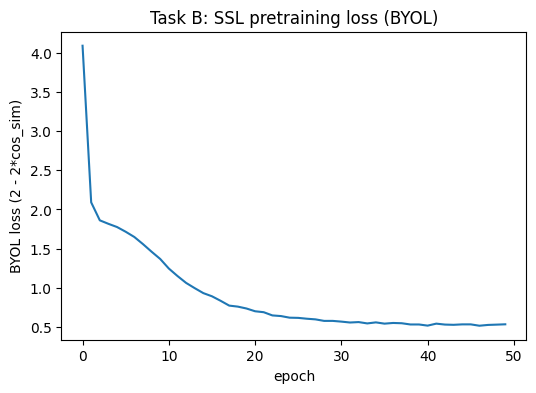

In [23]:
# built with AI assistance (Claude) -- disclosed per Sec. 7 AI Usage Policy

os.makedirs(f"{CONFIG['out_dir']}/ssl_ckpts", exist_ok=True)
ssl_loss_history, ssl_epoch_times = [], []

for epoch in range(CONFIG["ssl_epochs"]):
    t0 = time.time()
    for g in optimizer.param_groups:
        g["lr"] = lr_sched[epoch]

    online.train()
    running_loss, n_batches = 0.0, 0
    for v1, v2 in ssl_loader:
        v1, v2 = v1.to(DEVICE, non_blocking=True), v2.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast():
            p1 = online(v1)
            p2 = online(v2)
            with torch.no_grad():
                z1 = target(v1)
                z2 = target(v2)
            # symmetric loss: predict view2's target-branch output from view1's online branch,
            # and vice versa -- both directions matter (Grill et al. 2020, Sec 3.1)
            loss = (byol_loss(p1, z2) + byol_loss(p2, z1)).mean()

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            m = mom_sched[epoch]
            for po, pt in zip(online.encoder.parameters(), target.encoder.parameters()):
                pt.data.mul_(m).add_((1 - m) * po.detach().data)
            for po, pt in zip(online.projector.parameters(), target.projector.parameters()):
                pt.data.mul_(m).add_((1 - m) * po.detach().data)

        running_loss += loss.item(); n_batches += 1

    epoch_loss = running_loss / n_batches
    epoch_time = time.time() - t0
    ssl_loss_history.append(epoch_loss)
    ssl_epoch_times.append(epoch_time)
    print(f"[SSL] epoch {epoch+1}/{CONFIG['ssl_epochs']} | loss={epoch_loss:.4f} | {epoch_time:.1f}s/epoch")

    if (epoch + 1) % 10 == 0 or epoch == CONFIG["ssl_epochs"] - 1:
        torch.save(online.encoder.state_dict(), f"{CONFIG['out_dir']}/ssl_ckpts/byol_encoder_ep{epoch+1}.pth")

print(f"Avg per-epoch SSL time: {np.mean(ssl_epoch_times):.1f}s "
      f"({'>10min -> consider splitting into pretrain/downstream notebooks' if np.mean(ssl_epoch_times) > 600 else 'OK within a single notebook'})")

plt.figure(figsize=(6,4))
plt.plot(ssl_loss_history)
plt.xlabel("epoch"); plt.ylabel("BYOL loss (2 - 2*cos_sim)"); plt.title("Task B: SSL pretraining loss (BYOL)")
plt.savefig(f"{CONFIG['out_dir']}/byol_ssl_loss_curve.png", dpi=150); plt.show()

# use the SSL-pretrained online encoder going forward
pretrained_encoder = online.encoder

## Task C: SegFormer-style All-MLP decoder on ResNet-50 (adapter + full model) — same decoder design as Part A

In [24]:
class SegFormerStyleHead(nn.Module):
    """Re-implementation of HF SegformerDecodeHead's All-MLP head -- the decoder design your
    group found best-performing in Part A, reused unmodified in spirit across every SSL method's
    notebook so Task E's comparison is apples-to-apples (Sec. 3.3 of the PDF)."""
    def __init__(self, in_channels_list, embed_dim, num_classes, dropout=0.1):
        super().__init__()
        self.linear_c = nn.ModuleList([nn.Linear(c, embed_dim) for c in in_channels_list])
        self.linear_fuse = nn.Conv2d(embed_dim * len(in_channels_list), embed_dim, kernel_size=1, bias=False)
        self.batch_norm = nn.BatchNorm2d(embed_dim)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Conv2d(embed_dim, num_classes, kernel_size=1)

    def forward(self, feature_maps):
        # feature_maps must already share one (H, W) grid -- see get_adapted_multiscale() below,
        # which is where ResNet-50's *spatial* Task-C adapter (as opposed to DINOv2's *token -> 2D
        # grid* adapter) makes that true before this head ever sees the features.
        projected = []
        for fmap, proj in zip(feature_maps, self.linear_c):
            B, C, H, W = fmap.shape
            x = fmap.flatten(2).transpose(1, 2)      # (B, HW, C)
            x = proj(x)                               # (B, HW, embed_dim)
            x = x.transpose(1, 2).reshape(B, -1, H, W)
            projected.append(x)
        x = torch.cat(projected, dim=1)
        x = self.linear_fuse(x)
        x = self.batch_norm(x)
        x = self.activation(x)
        x = self.dropout(x)
        return self.classifier(x)


def get_adapted_multiscale(encoder, pixel_values):
    """Task C adapter for a *hierarchical* CNN encoder. ResNet-50's four stages are already
    genuinely multi-scale (unlike DINOv2's single-resolution ViT tokens, which needed a
    token-sequence -> 2D-grid reshape instead). What ResNet-50 needs is the opposite fix:
    SegFormerStyleHead's concat step assumes every tap already shares one (H, W) grid, so we
    bilinear-upsample C3/C4/C5 up to C2's resolution (stride 4) before handing them over. This
    is the spatial analogue of DINOv2's reshape adapter -- be ready to explain it at viva."""
    maps = encoder.forward_multiscale(pixel_values)      # [C2, C3, C4, C5], 4 different (H, W)
    target_hw = maps[0].shape[-2:]
    adapted = [maps[0]] + [F.interpolate(m, size=target_hw, mode="bilinear", align_corners=False)
                            for m in maps[1:]]
    return adapted


class ByolSegModel(nn.Module):
    def __init__(self, encoder, embed_dim_decoder, num_classes, freeze_encoder=False):
        super().__init__()
        self.encoder = encoder
        self.head = SegFormerStyleHead(encoder.out_channels, embed_dim_decoder, num_classes)
        self.set_encoder_frozen(freeze_encoder)

    def set_encoder_frozen(self, freeze: bool):
        for p in self.encoder.parameters():
            p.requires_grad = not freeze
        self.frozen = freeze

    def forward(self, pixel_values):
        H, W = pixel_values.shape[-2:]
        maps = get_adapted_multiscale(self.encoder, pixel_values)
        logits = self.head(maps)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)

## Frozen vs fine-tuned ablation (required by PDF for ≥1 SSL method — done here for BYOL)

In [25]:
def quick_train_eval(freeze_encoder, epochs=8, tag=""):
    model = ByolSegModel(copy.deepcopy(pretrained_encoder), CONFIG["decoder_embed_dim"],
                          CONFIG["num_classes"], freeze_encoder).to(DEVICE)
    params = [{"params": model.head.parameters(), "lr": CONFIG["ft_lr_decoder"]}]
    if not freeze_encoder:
        params.append({"params": model.encoder.parameters(), "lr": CONFIG["ft_lr_encoder"]})
    opt = torch.optim.AdamW(params, weight_decay=CONFIG["ft_weight_decay"])
    ce = nn.CrossEntropyLoss()

    for ep in range(epochs):
        model.train()
        for imgs, masks in ft_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            logits = model(imgs)
            loss = ce(logits, masks)
            opt.zero_grad(); loss.backward(); opt.step()

    model.eval()
    inter = torch.zeros(CONFIG["num_classes"]); union = torch.zeros(CONFIG["num_classes"])
    with torch.no_grad():
        for imgs, masks in test_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs).argmax(1)
            for c in range(CONFIG["num_classes"]):
                p, g = (preds == c), (masks == c)
                inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
    miou = (inter / union.clamp(min=1)).mean().item()
    print(f"[{tag}] {epochs}-epoch probe mIoU on test split: {miou:.4f}")
    return miou

miou_frozen   = quick_train_eval(freeze_encoder=True,  tag="FROZEN (linear probe)")
miou_finetune = quick_train_eval(freeze_encoder=False, tag="FINE-TUNED")

CONFIG["encoder_mode"] = "finetune" if miou_finetune >= miou_frozen else "frozen"
print(f"-> Chosen strategy for the full Task D run: {CONFIG['encoder_mode']}  "
      f"(frozen={miou_frozen:.4f} vs finetuned={miou_finetune:.4f})")

[FROZEN (linear probe)] 8-epoch probe mIoU on test split: 0.1761
[FINE-TUNED] 8-epoch probe mIoU on test split: 0.2524
-> Chosen strategy for the full Task D run: finetune  (frozen=0.1761 vs finetuned=0.2524)


## Task D: full supervised fine-tuning (50 epochs, monitored on test split)

[FT] epoch 1/50 | train_loss=2.4660 | monitor_mIoU(test)=0.0840 | 99.9s
[FT] epoch 2/50 | train_loss=1.2941 | monitor_mIoU(test)=0.1101 | 100.0s
[FT] epoch 3/50 | train_loss=0.8655 | monitor_mIoU(test)=0.1303 | 100.2s
[FT] epoch 4/50 | train_loss=0.6659 | monitor_mIoU(test)=0.1606 | 100.1s
[FT] epoch 5/50 | train_loss=0.5628 | monitor_mIoU(test)=0.1880 | 100.1s
[FT] epoch 6/50 | train_loss=0.4991 | monitor_mIoU(test)=0.2104 | 100.2s
[FT] epoch 7/50 | train_loss=0.4496 | monitor_mIoU(test)=0.2313 | 100.2s
[FT] epoch 8/50 | train_loss=0.4243 | monitor_mIoU(test)=0.2514 | 100.1s
[FT] epoch 9/50 | train_loss=0.3907 | monitor_mIoU(test)=0.2578 | 100.0s
[FT] epoch 10/50 | train_loss=0.3655 | monitor_mIoU(test)=0.2728 | 99.9s
[FT] epoch 11/50 | train_loss=0.3482 | monitor_mIoU(test)=0.2853 | 100.2s
[FT] epoch 12/50 | train_loss=0.3270 | monitor_mIoU(test)=0.2963 | 100.1s
[FT] epoch 13/50 | train_loss=0.3220 | monitor_mIoU(test)=0.3036 | 100.1s
[FT] epoch 14/50 | train_loss=0.3072 | monitor_mI

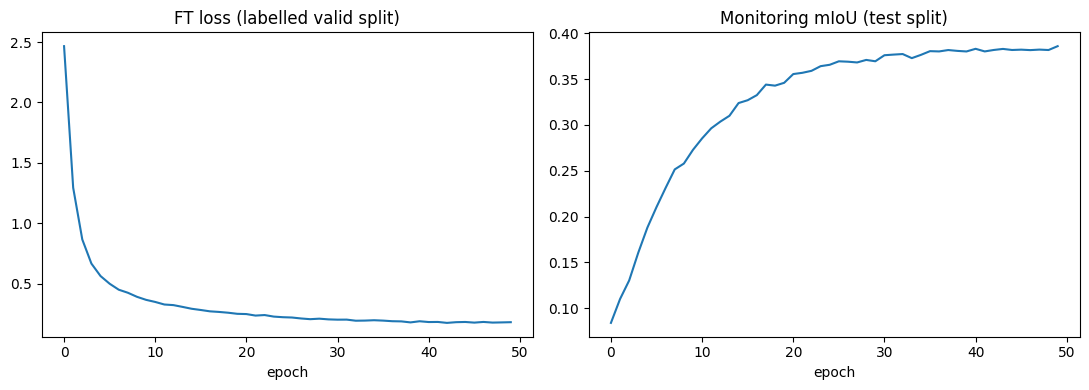

<All keys matched successfully>

In [26]:
freeze_final = (CONFIG["encoder_mode"] == "frozen")
model = ByolSegModel(pretrained_encoder, CONFIG["decoder_embed_dim"],
                      CONFIG["num_classes"], freeze_final).to(DEVICE)

param_groups = [{"params": model.head.parameters(), "lr": CONFIG["ft_lr_decoder"]}]
if not freeze_final:
    param_groups.append({"params": model.encoder.parameters(), "lr": CONFIG["ft_lr_encoder"]})
optimizer_ft = torch.optim.AdamW(param_groups, weight_decay=CONFIG["ft_weight_decay"])
scheduler_ft = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=CONFIG["ft_epochs"])
criterion = nn.CrossEntropyLoss()

def compute_miou(model, loader):
    model.eval()
    inter = torch.zeros(CONFIG["num_classes"]); union = torch.zeros(CONFIG["num_classes"])
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs).argmax(1)
            for c in range(CONFIG["num_classes"]):
                p, g = (preds == c), (masks == c)
                inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
    return (inter / union.clamp(min=1)).mean().item()

train_loss_hist, monitor_miou_hist, ft_epoch_times = [], [], []
best_miou, best_state = -1, None

for epoch in range(CONFIG["ft_epochs"]):
    t0 = time.time()
    model.train()
    running = 0.0
    for imgs, masks in ft_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = model(imgs)
        loss = criterion(logits, masks)
        optimizer_ft.zero_grad(); loss.backward(); optimizer_ft.step()
        running += loss.item()
    scheduler_ft.step()
    epoch_loss = running / len(ft_loader)
    monitor_miou = compute_miou(model, test_loader)   # test split double-role: monitoring here
    epoch_time = time.time() - t0

    train_loss_hist.append(epoch_loss); monitor_miou_hist.append(monitor_miou); ft_epoch_times.append(epoch_time)
    print(f"[FT] epoch {epoch+1}/{CONFIG['ft_epochs']} | train_loss={epoch_loss:.4f} | "
          f"monitor_mIoU(test)={monitor_miou:.4f} | {epoch_time:.1f}s")

    if monitor_miou > best_miou:
        best_miou, best_state = monitor_miou, copy.deepcopy(model.state_dict())

torch.save(best_state, f"{CONFIG['out_dir']}/byol_seg_best.pth")
print(f"Avg per-epoch FT time: {np.mean(ft_epoch_times):.1f}s | Best monitor mIoU: {best_miou:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(train_loss_hist); axes[0].set_title("FT loss (labelled valid split)"); axes[0].set_xlabel("epoch")
axes[1].plot(monitor_miou_hist); axes[1].set_title("Monitoring mIoU (test split)"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{CONFIG['out_dir']}/byol_ft_curves.png", dpi=150); plt.show()

model.load_state_dict(best_state)

## Task E: final test metrics + label-efficiency comparison

In [27]:
model.eval()
num_c = CONFIG["num_classes"]
inter = torch.zeros(num_c); union = torch.zeros(num_c); correct_c = torch.zeros(num_c); total_c = torch.zeros(num_c)
conf_mat = torch.zeros(num_c, num_c, dtype=torch.int64)
correct_px, total_px = 0, 0
dice_inter = torch.zeros(num_c); dice_sum = torch.zeros(num_c)

with torch.no_grad():
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = model(imgs).argmax(1)
        correct_px += (preds == masks).sum().item(); total_px += masks.numel()
        for c in range(num_c):
            p, g = (preds == c), (masks == c)
            inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
            dice_inter[c] += (p & g).sum().item(); dice_sum[c] += p.sum().item() + g.sum().item()
            correct_c[c] += (p & g).sum().item(); total_c[c] += g.sum().item()

        # --- vectorized confusion matrix update ---
        t_flat = masks.flatten().cpu()
        p_flat = preds.flatten().cpu()
        idx = t_flat * num_c + p_flat
        conf_mat += torch.bincount(idx, minlength=num_c * num_c).reshape(num_c, num_c)

per_class_iou = (inter / union.clamp(min=1)).numpy()
per_class_dice = (2 * dice_inter / dice_sum.clamp(min=1)).numpy()
per_class_acc = (correct_c / total_c.clamp(min=1)).numpy()

test_mIoU = float(np.mean(per_class_iou))
pixel_acc = correct_px / total_px
mean_pixel_acc = float(np.mean(per_class_acc))

byol_summary = {
    "model": f"BYOL-Seg (ResNet-50, {CONFIG['encoder_mode']})",
    "test_mIoU": test_mIoU,
    "test_pixel_acc": pixel_acc,
    "test_mean_pixel_acc": mean_pixel_acc,
    "labelled_finetune_images": len(valid_imgs),
    "num_params_millions": sum(p.numel() for p in model.parameters()) / 1e6,
}
print(json.dumps(byol_summary, indent=2))

per_class_df = pd.DataFrame({
    "class_id": range(num_c), "class_name": CLASS_NAMES,
    "IoU": per_class_iou, "PixelAcc": per_class_acc, "Dice": per_class_dice,
})
per_class_df.to_csv(f"{CONFIG['out_dir']}/byol_test_metrics_per_class.csv", index=False)

conf_df = pd.DataFrame(conf_mat.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES)
conf_df.to_csv(f"{CONFIG['out_dir']}/byol_confusion_matrix.csv")

# --- label-efficiency comparison vs Part-A baseline (same fixed number used in the DINOv2
# notebook -- keep this identical across all 4 SSL-method notebooks for a fair comparison) ---
PART_A_BASELINE = {"model": "SegFormer-B0 (Part-A, fully supervised)",
                    "test_mIoU": 0.4800178820641928, "train_images": len(train_imgs)}

comparison = pd.DataFrame([
    {"Model": PART_A_BASELINE["model"], "Test mIoU": PART_A_BASELINE["test_mIoU"],
     "Labelled images used": PART_A_BASELINE["train_images"]},
    {"Model": byol_summary["model"], "Test mIoU": byol_summary["test_mIoU"],
     "Labelled images used": len(valid_imgs)},
])
comparison["Label ratio vs Part-A"] = comparison["Labelled images used"] / PART_A_BASELINE["train_images"]
print(comparison.to_string(index=False))

{
  "model": "BYOL-Seg (ResNet-50, finetune)",
  "test_mIoU": 0.38585585355758667,
  "test_pixel_acc": 0.9336832819174099,
  "test_mean_pixel_acc": 0.481324702501297,
  "labelled_finetune_images": 697,
  "num_params_millions": 24.772228
}
                                  Model  Test mIoU  Labelled images used  Label ratio vs Part-A
SegFormer-B0 (Part-A, fully supervised)   0.480018                  2473               1.000000
         BYOL-Seg (ResNet-50, finetune)   0.385856                   697               0.281844


## Task F: error analysis (worst-K predictions)

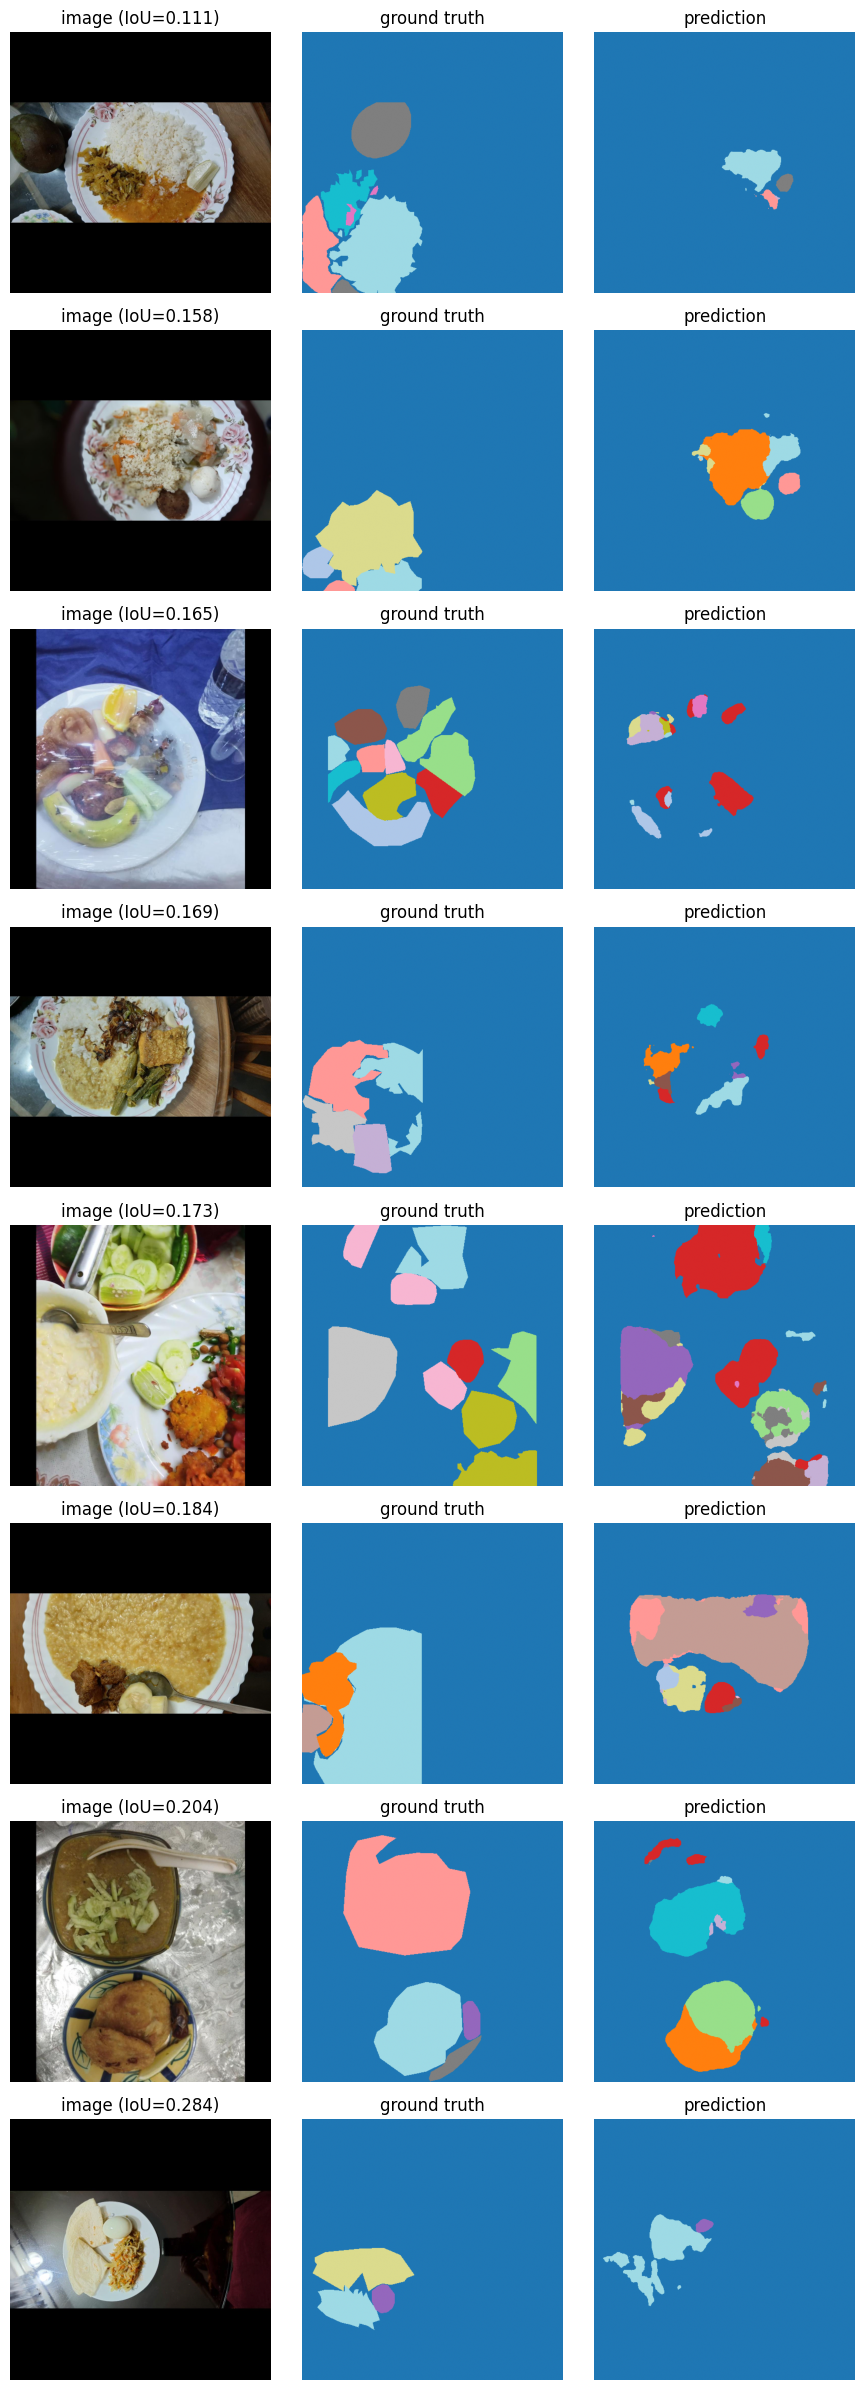

In [28]:
def per_image_miou(model, loader, k=8):
    model.eval()
    scores = []
    with torch.no_grad():
        for bi, (imgs, masks) in enumerate(loader):
            imgs_d, masks_d = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs_d).argmax(1)
            for i in range(imgs.shape[0]):
                p, g = preds[i], masks_d[i]
                ious = []
                for c in torch.unique(g).tolist():
                    pc, gc = (p == c), (g == c)
                    u = (pc | gc).sum().item()
                    if u > 0:
                        ious.append((pc & gc).sum().item() / u)
                scores.append((np.mean(ious), bi, i, imgs[i].cpu(), masks[i].cpu(), p.cpu()))
    scores.sort(key=lambda x: x[0])
    return scores[:k]

worst = per_image_miou(model, test_loader, k=8)
fig, axes = plt.subplots(len(worst), 3, figsize=(9, 3*len(worst)))
for row, (score, bi, i, img, gt, pred) in enumerate(worst):
    axes[row,0].imshow(denorm(img)); axes[row,0].set_title(f"image (IoU={score:.3f})"); axes[row,0].axis("off")
    axes[row,1].imshow(gt, cmap="tab20"); axes[row,1].set_title("ground truth"); axes[row,1].axis("off")
    axes[row,2].imshow(pred, cmap="tab20"); axes[row,2].set_title("prediction"); axes[row,2].axis("off")
plt.tight_layout(); plt.savefig(f"{CONFIG['out_dir']}/byol_worst_predictions.png", dpi=150); plt.show()

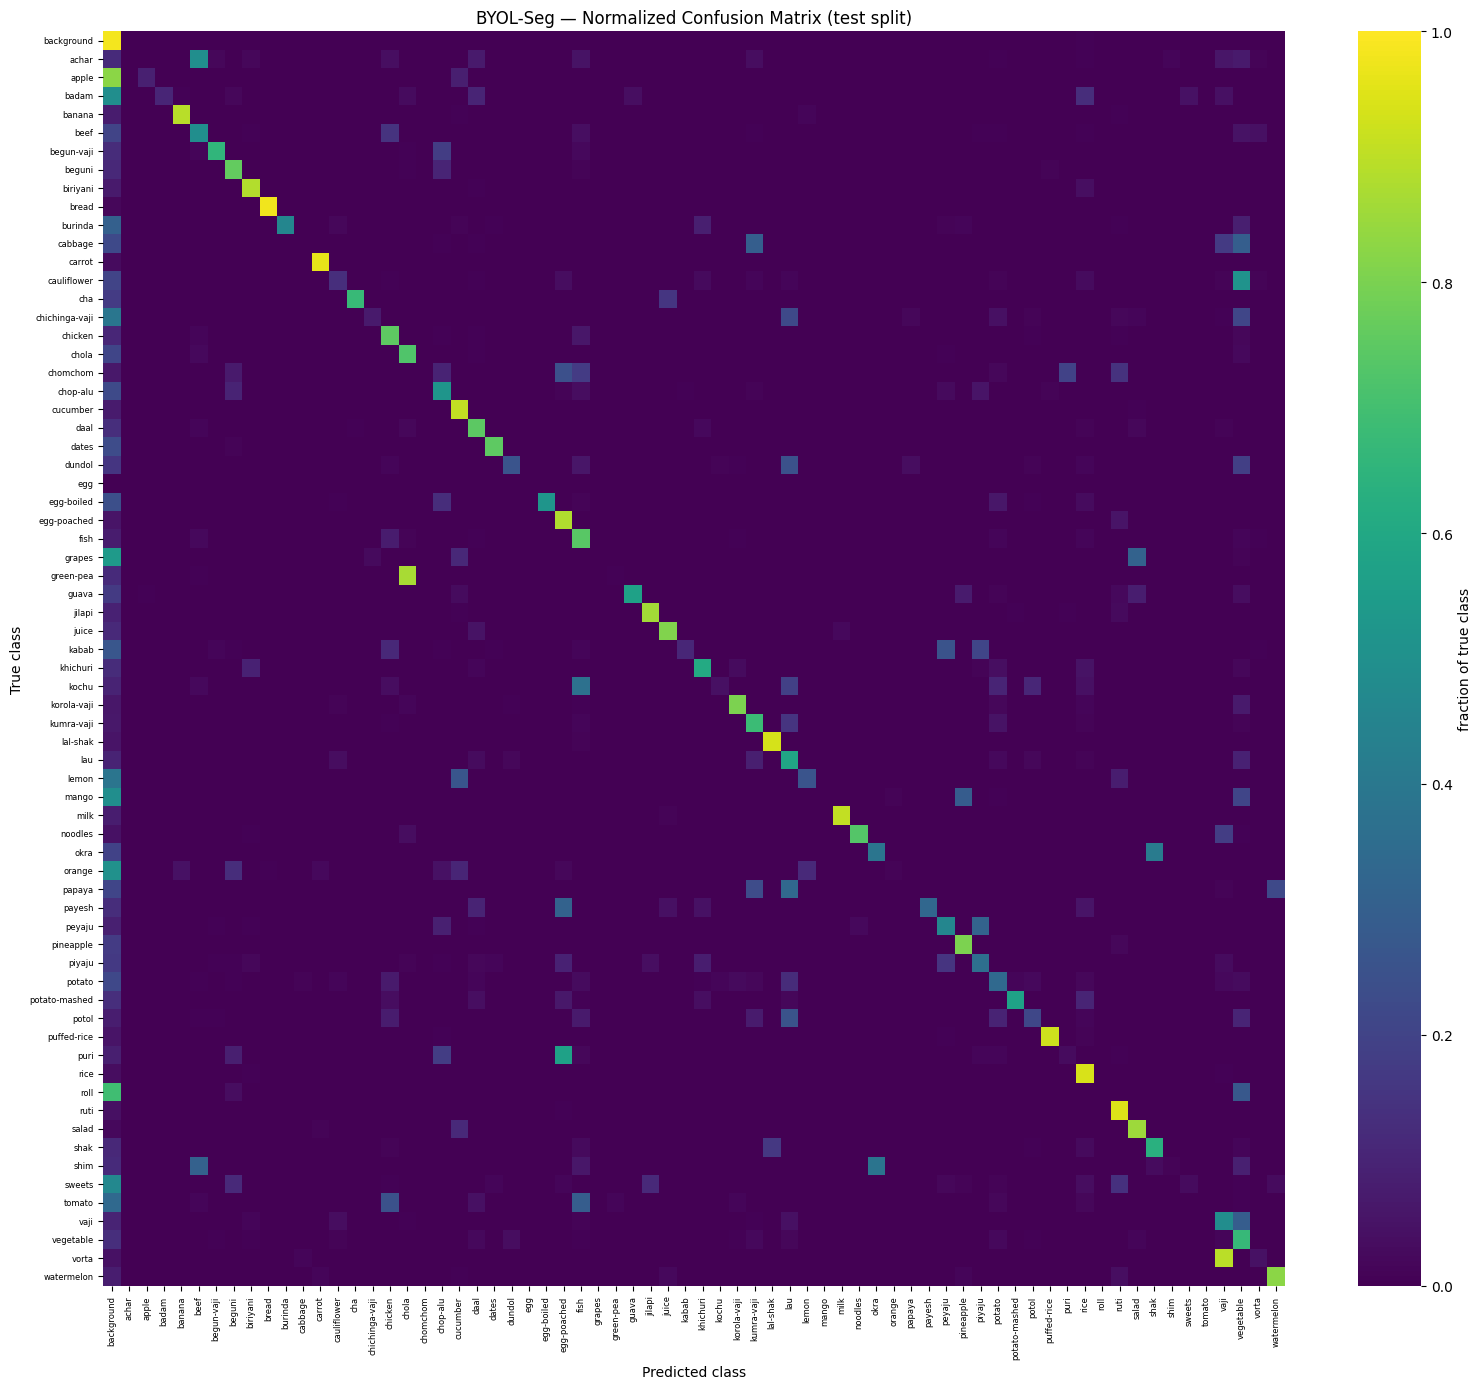

    true_class predicted_as  pixel_count  fraction_of_true_class
         vorta         vaji         7853                0.895541
     green-pea        chola         7027                0.868925
         apple   background         2794                0.826383
          roll   background         4103                0.695188
          puri  egg-poached        73370                0.571538
        grapes   background        14916                0.539516
   cauliflower    vegetable        52174                0.513215
        orange   background         4667                0.502260
         achar         beef        45710                0.491373
         badam   background        22471                0.491320
         mango   background        16296                0.489855
        sweets   background        20833                0.464929
          okra         shak        17730                0.413325
chichinga-vaji   background        24376                0.391746
         lemon   backgrou

In [29]:
import seaborn as sns

# --- normalize confusion matrix by row (true class) so each row sums to 1 ---
conf_np = conf_mat.numpy().astype(np.float64)
row_sums = conf_np.sum(axis=1, keepdims=True)
conf_norm = np.divide(conf_np, row_sums, out=np.zeros_like(conf_np), where=row_sums != 0)

# --- full heatmap ---
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(conf_norm, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "fraction of true class"})
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("BYOL-Seg — Normalized Confusion Matrix (test split)")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig(f"{CONFIG['out_dir']}/byol_confusion_matrix_heatmap.png", dpi=200)
plt.show()

# --- top-20 off-diagonal confusions (the pairs actually worth discussing in Task F) ---
off_diag = []
for i in range(num_c):
    for j in range(num_c):
        if i != j and conf_mat[i, j] > 0:
            off_diag.append((CLASS_NAMES[i], CLASS_NAMES[j], int(conf_mat[i, j]), conf_norm[i, j]))

confusion_df = pd.DataFrame(off_diag, columns=["true_class", "predicted_as", "pixel_count", "fraction_of_true_class"])
confusion_df = confusion_df.sort_values("fraction_of_true_class", ascending=False).head(20)
confusion_df.to_csv(f"{CONFIG['out_dir']}/byol_top_confusions.csv", index=False)
print(confusion_df.to_string(index=False))

## Append to shared results.json (for the Final Comparison notebook)

In [30]:
results_path = f"{CONFIG['out_dir']}/results.json"
all_results = {}
if os.path.exists(results_path):
    all_results = json.load(open(results_path))
all_results["byol"] = {**byol_summary,
                        "frozen_probe_miou": miou_frozen, "finetuned_probe_miou": miou_finetune,
                        "chosen_strategy": CONFIG["encoder_mode"],
                        "ssl_avg_epoch_time_s": float(np.mean(ssl_epoch_times)),
                        "ft_avg_epoch_time_s": float(np.mean(ft_epoch_times))}
json.dump(all_results, open(results_path, "w"), indent=2)
print("Saved:", results_path)

# NOTE: copy this notebook's /kaggle/working/byol_outputs/results.json entry ("byol": {...})
# into the same shared results.json used by SimCLR/MAE/DINOv2 + your Final Comparison notebook
# (e.g. via a Kaggle Dataset output, same pattern as the other 3 method notebooks).

Saved: /kaggle/working/byol_outputs/results.json
